<a href="https://colab.research.google.com/github/Lord-LLM/scratch/blob/main/PROBABILITY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

np.random.seed(42)
print("Libraries succesfully loaded")

Libraries succesfully loaded


In [3]:
# Activities: 0 = sleep, 1 = programming, 2 = classes , 3 = football, 4 = cooking
historical_activities = [0, 1, 2, 4, 3, 1, 2, 1, 3, 4, 1, 2, 1, 4, 2, 2, 1]

In [4]:
# Calculate probabilities
def calculate_probabilities(sequence):
  counts = Counter(sequence)
  total = len(sequence)
  probabilities={
      activity: counts/total
      for activity, counts in counts.items()
  }
  return probabilities


In [5]:
# Activity probabilities
activity_probabilities = calculate_probabilities(historical_activities)

In [7]:
# Activity names
activity_names = {
    0: "sleep",
    1: "programming",
    2: "classes",
    3: "football",
    4: "cooking"
}

In [8]:
for activity, probability in activity_probabilities.items():
  print(f"{activity_names[activity]}: {probability}")

sleep: 0.058823529411764705
programming: 0.35294117647058826
classes: 0.29411764705882354
cooking: 0.17647058823529413
football: 0.11764705882352941


In [10]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After sleep:
  → programming: 100.00%

After programming:
  → classes: 60.00%
  → football: 20.00%
  → cooking: 20.00%

After classes:
  → programming: 60.00%
  → classes: 20.00%
  → cooking: 20.00%

After cooking:
  → programming: 33.33%
  → classes: 33.33%
  → football: 33.33%

After football:
  → programming: 50.00%
  → cooking: 50.00%



In [14]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):

    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will sleep based on features
# Features: [hours_of_work, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.8])  # 7 hours work, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.8, 0.2, 0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of sleeping: {prediction:.2%}")
print(f"Prediction: {'Will sleep' if prediction > 0.5 else 'Will not sleep'}")

Probability of sleeping: 99.77%
Prediction: Will sleep


In [15]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

np.random.seed(42)
X_train = np.random.rand(100, 4)
# Simulate pattern: social activity more likely on weekends (day > 5) and good weather
y_train = ((X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2  # Add noise
y_train = np.clip(y_train, 0, 1)

# Create and train network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)

Training neural network...

Epoch 0, Loss: 0.5069
Epoch 100, Loss: 0.1061
Epoch 200, Loss: 0.0863
Epoch 300, Loss: 0.0678
Epoch 400, Loss: 0.0550


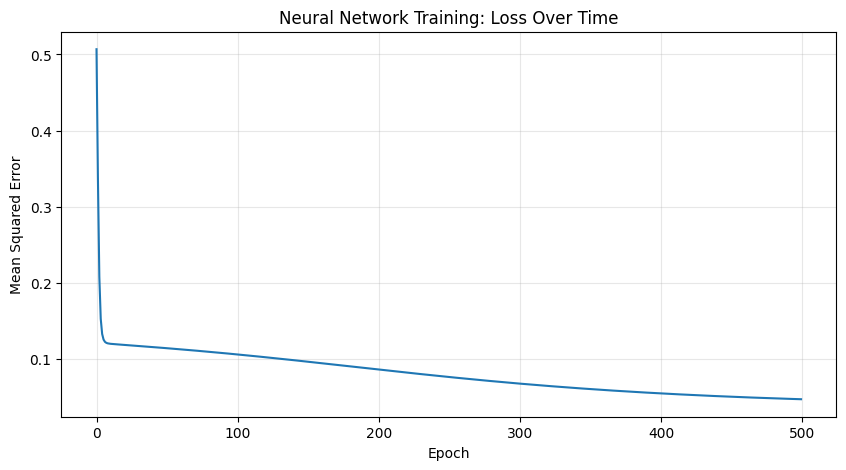


Final loss: 0.0474


In [16]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")
